# Group C – Decision Trees
## Identifying penguin species from body measurements

**Dataset:** *Palmer Penguins*, collected by Dr. Kristen Gorman at Palmer Station, Antarctica. It has 344 penguins
from three species (**Adelie, Chinstrap, Gentoo**), with bill length, bill depth, flipper length and body mass.

**Question:** Can a decision tree learn simple *if/else rules* that identify a penguin's species from its measurements?

The class example built a tree on a tiny made-up hiring CSV with yes/no answers. Here I use real numeric field data with
**three classes**, test the tree on unseen penguins, and control its depth to avoid overfitting.

### How a Decision Tree works
A decision tree is a flowchart of yes/no questions such as *"Is flipper length ≤ 206 mm?"*.

To build it, the algorithm starts with all the training data and:
1. Tries every feature and every possible threshold
2. Picks the split that makes the two resulting groups as **pure** as possible (each group mostly one species).
   Purity is measured with **Gini impurity**: $Gini = 1 - \sum_k p_k^2$. It is 0 when a group is all one class.
3. Repeats the process on each group (**recursively**) until the groups are pure or a stopping rule is reached (for example, `max_depth`)

To make a prediction, a new penguin starts at the top and follows the answers down to a **leaf**. The leaf's
majority species is the prediction.

If nothing stops it, a tree keeps splitting until every training example is classified perfectly, which is **overfitting**. Limiting the depth keeps the rules general.

In [1]:
%matplotlib inline
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay


def load_data(name):
    """Load a dataset from the local data/ folder, or download it from seaborn if not found (e.g. in Colab)."""
    for path in (f"data/{name}.csv", f"{name}.csv"):
        if os.path.exists(path):
            return pd.read_csv(path)
    return sns.load_dataset(name)

### 1. Load and explore the data

In [2]:
penguins = load_data("penguins").dropna()      # drop the 11 penguins with missing measurements
features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
print(penguins.shape)
print(penguins["species"].value_counts())
penguins.head()

(333, 7)
species
Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male


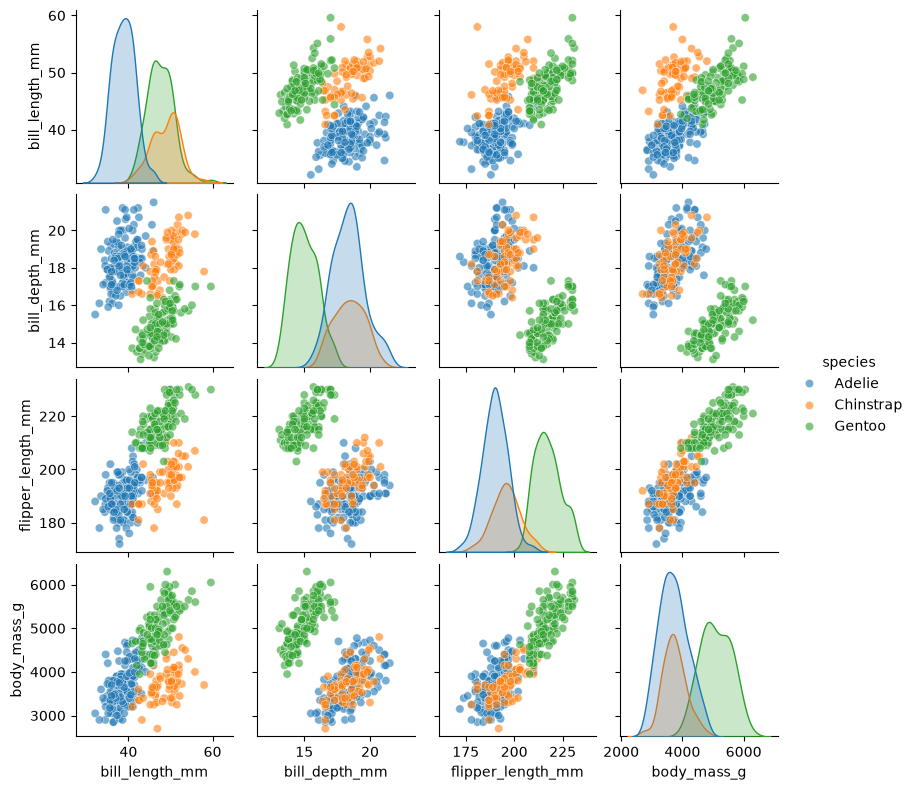

In [3]:
sns.pairplot(penguins, vars=features, hue="species", height=2, plot_kws={"alpha": 0.6})
plt.show()

The pair plot already suggests some rules:
* **Gentoo** penguins have much longer flippers than the other two species
* **Adelie** and **Chinstrap** have similar flippers but differ in **bill length**. Chinstraps have longer bills.

Let's see if the decision tree finds the same rules on its own.

In [4]:
X = penguins[features]
y = penguins["species"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print(f"Training: {len(X_train)} penguins, Test: {len(X_test)} penguins")

Training: 249 penguins, Test: 84 penguins


### 2. How deep should the tree be?
I train trees of different maximum depths and compare training accuracy with 5-fold cross-validated accuracy.

In [5]:
rows = []
for depth in [1, 2, 3, 4, 5, None]:          # None = no limit, the tree grows until every leaf is pure
    clf = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(X_train, y_train)
    cv = cross_val_score(DecisionTreeClassifier(max_depth=depth, random_state=42), X_train, y_train, cv=5).mean()
    rows.append({"max_depth": str(depth), "leaves": clf.get_n_leaves(),
                 "train accuracy": clf.score(X_train, y_train), "cross-val accuracy": cv})
pd.DataFrame(rows).round(3)

,max_depth,leaves,train accuracy,cross-val accuracy
0,1,2,0.787,0.787
1,2,4,0.964,0.952
2,3,7,0.972,0.952
3,4,10,0.996,0.968
4,5,11,1.000,0.960
5,None,11,1.000,0.960


* **Depth 1** can only ask one question, so it can't separate three species (underfitting).
* With **no limit**, the tree reaches 100% training accuracy by adding extra leaves for a few unusual penguins. Cross-validation
  shows this doesn't really help on new penguins.
* Depth 4 scores slightly higher in cross-validation (96.8% vs 95.2%), but it needs 10 leaves instead of 7. Its extra splits each handle only a few penguins.
* Depths **2–3** get almost all the accuracy with only a handful of rules. I use **max_depth = 3**, trading about 1.6% accuracy for a tree small enough to read and explain.

### 3. Train and visualise the final tree

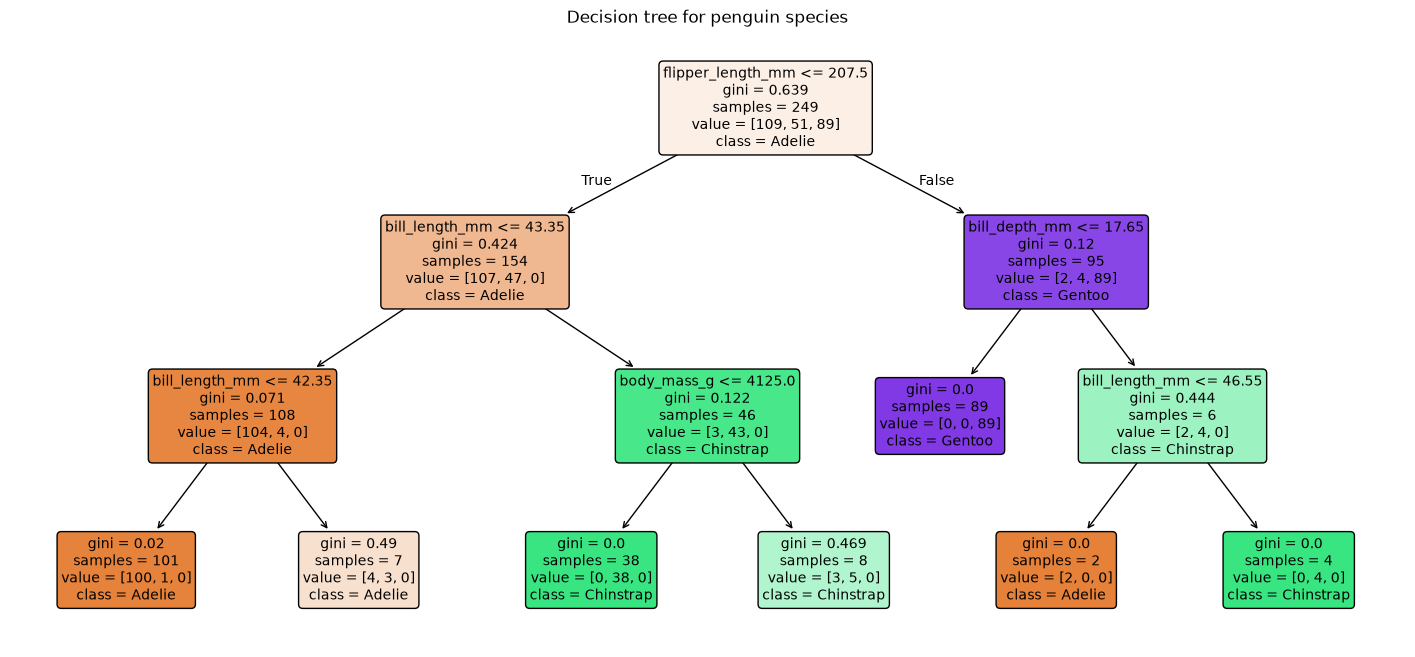

In [6]:
tree_model = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)

plt.figure(figsize=(18, 8))
plot_tree(tree_model, feature_names=features, class_names=tree_model.classes_,
          filled=True, rounded=True, fontsize=10)
plt.title("Decision tree for penguin species")
plt.show()

**How to read the tree:** each box shows the question asked, its **Gini** impurity, how many training penguins reached it,
the count of each species (`value = [Adelie, Chinstrap, Gentoo]`) and the majority class. "True" goes **left** and "False" goes **right**.
The colour shows the majority species, and stronger colour means a purer group.

The same tree as text rules:

In [7]:
print(export_text(tree_model, feature_names=features))

|--- flipper_length_mm <= 207.50
|   |--- bill_length_mm <= 43.35
|   |   |--- bill_length_mm <= 42.35
|   |   |   |--- class: Adelie
|   |   |--- bill_length_mm >  42.35
|   |   |   |--- class: Adelie
|   |--- bill_length_mm >  43.35
|   |   |--- body_mass_g <= 4125.00
|   |   |   |--- class: Chinstrap
|   |   |--- body_mass_g >  4125.00
|   |   |   |--- class: Chinstrap
|--- flipper_length_mm >  207.50
|   |--- bill_depth_mm <= 17.65
|   |   |--- class: Gentoo
|   |--- bill_depth_mm >  17.65
|   |   |--- bill_length_mm <= 46.55
|   |   |   |--- class: Adelie
|   |   |--- bill_length_mm >  46.55
|   |   |   |--- class: Chinstrap



The tree found the **same rules we saw in the pair plot**, without being told:
1. **First question, flipper length ≤ ~207 mm?** This separates almost all **Gentoos** (long flippers) from the rest. It is the best first split because it removes a whole species at once.
2. On the short-flipper side, **bill length ≤ ~43 mm?** separates **Adelie** (short bills) from **Chinstrap** (long bills).
3. On the long-flipper side, **bill depth** separates the Gentoos (thin, shallow bills) from a few large Adelies and Chinstraps.

The third level only refines the edges. Some of its splits end in two leaves with the same prediction, because they make the groups purer without changing the answer.

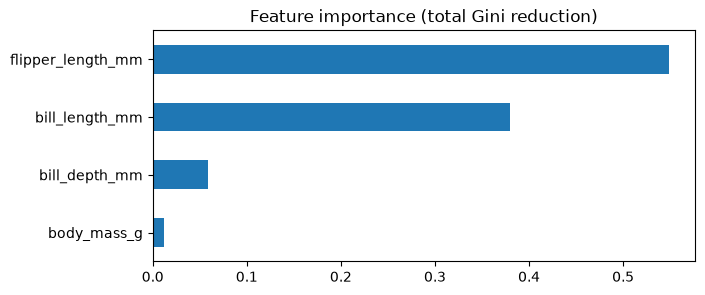

In [8]:
importance = pd.Series(tree_model.feature_importances_, index=features).sort_values()
importance.plot.barh(figsize=(7, 3), title="Feature importance (total Gini reduction)")
plt.show()

**Flipper length** and **bill length** do almost all of the work. Body mass is barely used.

### 4. Test on unseen penguins

Test accuracy: 0.952


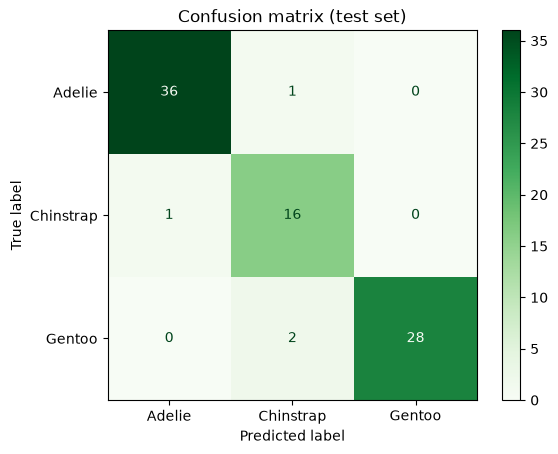

In [9]:
y_pred = tree_model.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.3f}")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Greens")
plt.title("Confusion matrix (test set)")
plt.show()

The tree correctly identifies about **95%** of penguins it has never seen. The few mistakes are mostly between
**Adelie and Chinstrap**. These species look similar, and a few penguins fall right on the bill-length threshold.

### 5. Classify some new penguins

In [10]:
new_penguins = pd.DataFrame([
    [39.0, 18.5, 190, 3700],   # short bill, short flipper
    [47.0, 15.0, 217, 5000],   # long flipper, thin bill, heavy
    [50.0, 19.0, 196, 3800],   # long bill, short flipper
], columns=features)
new_penguins["predicted species"] = tree_model.predict(new_penguins[features])
new_penguins

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,predicted species
0,39.0,18.5,190,3700,Adelie
1,47.0,15.0,217,5000,Gentoo
2,50.0,19.0,196,3800,Chinstrap


Following the rules by hand for the second penguin: flipper 217 mm > 207 → go right; bill depth 15 mm ≤ 17.65 → **Gentoo**. ✔

### Conclusion
* The decision tree learned **simple, readable rules** (flipper length first, then bill length or bill depth) that identify penguin species about **95%** of the time on new data.
* Limiting **max_depth** stopped the tree from memorising individual penguins (overfitting) and kept it easy to explain.
* Strengths: easy to interpret, and features don't need scaling because each split looks at only one feature at a time.
  Weaknesses: small changes in the data can produce a different tree, which is why ensembles like **Random Forests** average many trees.